In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



from caldis.core.system import System
from caldis.fluids import CoolPropBackend

from caldis.components import FluidBoundary
from caldis.components import Compressor

#SizingHX = recuperator
# SimpleHeater = inter /after-cooler

from caldis.components import SizingHX, SimpleHeater

#FlashTank
from caldis.components import FlashTank , Mixer , Valve

#only for L3
from caldis.components import Splitter
from caldis.solvers import solve        

from CoolProp.CoolProp import PropsSI

### Paramètres

In [18]:

gas = "Methane"
be_methane = CoolPropBackend(gas)
T0 = 273.15 + 25.0  # K

T_IC = T0 + 5.0 # K
T_aftercooler = T0 + 5.0 # K


P_high = 100e5

comp_is_e = 0.75 
HX_pinch = 5 # K
HP_recup_coeff = 1000 # W/m2K
LP_recup_coeff = 500 # W/m2K

mdot_liq = 1 # kg/s

# L0 : Baseline cycle

In [19]:
source    = FluidBoundary("source", T=T0, backend=be_methane, p=1e5)

Mixer_ = Mixer("Mixer", backend=be_methane)
# Compressors (4 compressors in series, with intercooling between each stage)

Comp1 = Compressor("Comp1", eta_is=comp_is_e, backend=be_methane)
Comp2 = Compressor("Comp2", eta_is=comp_is_e, backend=be_methane)
Comp3 = Compressor("Comp3", eta_is=comp_is_e, backend=be_methane)
Comp4 = Compressor("Comp4", eta_is=comp_is_e, backend=be_methane)

IC1 = SimpleHeater("IC1", backend=be_methane)
IC2 = SimpleHeater("IC2",backend=be_methane)
IC3 = SimpleHeater("IC3",backend=be_methane)

Aftercooler = SimpleHeater("Aftercooler", T_source=T_aftercooler, backend=be_methane)

Recuperator = SizingHX("Recuperator", h_hot = HP_recup_coeff, h_cold = LP_recup_coeff, backend_hot=be_methane, backend_cold=be_methane, area_ratio_cold_to_hot=1.0)

#Valve     def __init__(self, name, Kv=None, backend=None, flow_law="quadratic", eps=1e-9):
valve = Valve("valve", backend=be_methane)

Flash = FlashTank("Flash", backend=be_methane)

liquid_product = FluidBoundary("liquid_product", backend=be_methane)


In [20]:
sys = System("cycle")

sys.add( source, Comp1, IC1, Comp2, IC2, Comp3, IC3, Comp4, Aftercooler, Recuperator, valve, Flash, Mixer_, liquid_product)

sys.connect(source.port, Mixer_.in1)
#afficher les attributs de Comp1
#print(Comp1.attributes#)

sys.connect(Mixer_.out, Comp1.inl)
sys.connect(Comp1.out, IC1.inl)
sys.connect(IC1.out, Comp2.inl)
sys.connect(Comp2.out, IC2.inl)
sys.connect(IC2.out, Comp3.inl)
sys.connect(Comp3.out, IC3.inl)
sys.connect(IC3.out, Comp4.inl)

#after cooler
sys.connect(Comp4.out, Aftercooler.inl)
sys.connect(Aftercooler.out, Recuperator.hot_in)


#Recuperator
sys.connect(Recuperator.hot_out, valve.inl)
sys.connect(valve.out, Flash.inl)

sys.connect(Recuperator.cold_in, Flash.vap)
sys.connect(Recuperator.cold_out, Mixer_.in2)

sys.connect(Flash.liq, liquid_product.port)

# add constraints on the compressors, r=3.16 for all stages
sys.add_constraint(lambda: Comp1.out.p - 3.16 * Comp1.inl.p, "fn=comp1_pressure_ratio")
sys.add_constraint(lambda: Comp2.out.p - 3.16 * Comp2.inl.p, "fn=comp2_pressure_ratio")
sys.add_constraint(lambda: Comp3.out.p - 3.16 * Comp3.inl.p, "fn=comp3_pressure_ratio")
sys.add_constraint(lambda: Comp4.out.p - 3.16 * Comp4.inl.p, "fn=comp4_pressure_ratio")

#refroidisseurs sortent à T0 + 5K:
sys.add_constraint(lambda hx=IC1: hx.out.T - T_IC, "fn=IC1_T_out")
sys.add_constraint(lambda hx=IC2: hx.out.T - T_IC, "fn=IC2_T_out")
sys.add_constraint(lambda hx=IC3: hx.out.T - T_IC, "fn=IC3_T_out")



sys.add_constraint(lambda: Aftercooler.out.T - T_aftercooler, "fn=aftercooler_temperature")


sys.add_constraint(lambda: liquid_product.port.mdot - mdot_liq, "fn=liquid_product_mass_flow")

sys.add_constraint(lambda: Recuperator.hot_in.T - Recuperator.cold_out.T - HX_pinch, "fn=recuperator_pinch")


# ne pas mettre cette contrainte sys.add_constraint(lambda: valve.out.p - 1e5, "fn=valve_outlet_pressure")

sol = solve(sys)



✓ DOF: square (97 unknowns)
✓ start point: evaluable
⚠ 10 start-sanity warning(s):
   - Comp1: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp2: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp3: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp4: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Recuperator: temperature cross at start (dT1=0.0, dT2=0.0 K)
   - Recuperator: hot inlet/outlet nearly equal -> LMTD/flow degenerate
   - Recuperator: cold inlet/outlet nearly equal -> cold MASS FLOW is undetermined (anchor the cold-side inlet/outlet TEMPERATURES)
   - Flash: vap mdot should be < 0 (outlet)
   - Flash: liq mdot should be < 0 (outlet)
   - Mixer: out mdot should be < 0 (outlet)
  (non-blocking.)
  direct Newton: failed -> fallback to homotopy (1 it, |F_scaled|=1.6e+01)
✗ FAILED: homotopy stuck at lambda=0.0000 (dlam<0.001): jacobienne singulière (it 1)

=== convergence report (FAILED) ===
message: homotop

### Now that the systeme is squared, let's impose realistic initial vales.

In [21]:
from caldis.solvers.autostart import autostart

pk = [1e5 * 3.16**k for k in range(5)]          # 1 ; 3,16 ; 9,99 ; 31,6 ; 99,7 bar
T_comp_out = [411.6, 417.9, 418.6, 420.4]       # K
comps, coolers = [Comp1, Comp2, Comp3, Comp4], [IC1, IC2, IC3, Aftercooler]

for k, (C, X) in enumerate(zip(comps, coolers)):
    sys.set_start_port(C.inl,  p=pk[k],   T=T0 if k == 0 else T_IC)
    sys.set_start_port(C.out,  p=pk[k+1], T=T_comp_out[k])
    sys.set_start_port(X.inl,  p=pk[k+1], T=T_comp_out[k])
    sys.set_start_port(X.out,  p=pk[k+1], T=T_IC)

for prt in (source.port, Mixer_.in1, Mixer_.in2, Mixer_.out):
    sys.set_start_port(prt, p=1e5, T=T0)

sys.set_start_port(Recuperator.hot_in,   p=pk[4], T=T_IC)
sys.set_start_port(Recuperator.hot_out,  p=pk[4], T=217.0)
sys.set_start_port(valve.inl,            p=pk[4], T=217.0)
sys.set_start_port(Recuperator.cold_in,  p=1e5,   T=113.0)  # vapeur sat., légèrement surchauffée
sys.set_start_port(Flash.vap,            p=1e5,   T=113.0)
sys.set_start_port(Recuperator.cold_out, p=1e5,   T=T0)
sys.set_start_port(Flash.liq,            p=1e5,   T=110.0)  # liquide sat., légèrement sous-refroidi

autostart(sys)
sol = solve(sys, verbose=True)

✓ DOF: square (97 unknowns)
✓ start point: evaluable
⚠ 3 start-sanity warning(s):
   - Flash: vap mdot should be < 0 (outlet)
   - Flash: liq mdot should be < 0 (outlet)
   - Mixer: out mdot should be < 0 (outlet)
  (non-blocking.)
  direct Newton: ok (8 it, |F_scaled|=2.0e-09)
✓ SOLVED (|F_scaled|=2.0e-09)


### MÉTRIQUES DU PARAGRAPHE « Comparison metrics »


In [22]:
# =====================================================================
# MÉTRIQUES DU PARAGRAPHE « Comparison metrics »
# =====================================================================
def w_min(fluid, T0, p_feed=1e5, p_prod=1e5):
    """Travail minimal réversible [J/kg] : T0*(s_feed - s_liq) - (h_feed - h_liq)."""
    s_f, h_f = (PropsSI(k, "T", T0, "P", p_feed, fluid) for k in ("S", "H"))
    s_l, h_l = (PropsSI(k, "Q", 0, "P", p_prod, fluid) for k in ("S", "H"))
    return T0 * (s_f - s_l) - (h_f - h_l)
 
 
def lng_metrics(compressors, liquid_port, circ_port, expanders=(), W_pre=0.0,
                fluid="Methane", T0=298.15):
    """y, w, figure de mérite.  Convention : Wtotal = Wcomp - Wexp + Wpre  (>0 = consommé).
    Wdot < 0 pour un compresseur, > 0 pour une turbine (convention des notebooks)."""
    m_liq, m_circ = abs(liquid_port.mdot), abs(circ_port.mdot)
    W_comp = -sum(c.Wdot for c in compressors)
    W_exp = sum(e.Wdot for e in expanders)
    W_tot = W_comp - W_exp + W_pre
    w = W_tot / m_liq
    wm = w_min(fluid, T0)
    return dict(y=m_liq / m_circ, m_circ=m_circ, W_comp=W_comp, W_exp=W_exp,
                W_tot=W_tot, w=w, w_kWh_per_kg=w / 3.6e6, w_min=wm, fom=wm / w)
 
 
def hx_profile(hx, fluid, n=200):
    """Profil T_chaud / T_froid le long du récupérateur (contre-courant, propriétés réelles).
    Sert à vérifier a posteriori le pincement INTERNE que le modèle mono-zone ne voit pas."""
    hi, ho, ci, co = hx.hot_in, hx.hot_out, hx.cold_in, hx.cold_out
    m_h, m_c = abs(hi.mdot), abs(ci.mdot)
    h_c = np.linspace(ci.h, co.h, n)                    # du bout froid au bout chaud
    h_h = ho.h + (m_c / m_h) * (h_c - ci.h)             # bilan d'énergie local
    T_c = np.array([PropsSI("T", "P", ci.p, "H", h, fluid) for h in h_c])
    T_h = np.array([PropsSI("T", "P", hi.p, "H", h, fluid) for h in h_h])
    return T_h, T_c
 
 
def energy_closure(source_port, liquid_port, machines, coolers):
    """1er principe sur tout le cycle (doit être ~0) :
    Q_reçu + W_reçu = m_liq*h_liq - m_source*h_source."""
    Q_in = sum(c.Qdot for c in coolers)
    W_in = -sum(m.Wdot for m in machines)
    out_minus_in = abs(liquid_port.mdot) * liquid_port.h - abs(source_port.mdot) * source_port.h
    return Q_in + W_in - out_minus_in

res = lng_metrics([Comp1, Comp2, Comp3, Comp4], liquid_product.port, Comp1.inl)
T_h, T_c = hx_profile(Recuperator, "Methane")          # pincement interne, vérification a posteriori
res = lng_metrics([Comp1, Comp2, Comp3, Comp4], liquid_product.port, Comp1.inl)
T_h, T_c = hx_profile(Recuperator, "Methane")
dT = T_h - T_c
bilan = energy_closure(source.port, liquid_product.port,
                       [Comp1, Comp2, Comp3, Comp4], [IC1, IC2, IC3, Aftercooler])

print("=" * 52)
print(f"{'RÉSULTATS L0':^52}")
print("=" * 52)
print(f"{'Rendement de liquéfaction y':<34}{100*res['y']:>10.2f} %      (attendu ≈ 9 %)")
print(f"{'Débit circulant':<34}{res['m_circ']:>10.2f} kg/s   (attendu ≈ 11)")
print(f"{'Travail de compression':<34}{res['W_comp']/1e6:>10.2f} MW")
print(f"{'Travail spécifique w':<34}{res['w']/1e3:>10.0f} kJ/kg   (attendu 1.1–1.2e4)")
print(f"{'':<34}{res['w_kWh_per_kg']:>10.2f} kWh/kg")
print(f"{'Travail minimal w_min':<34}{res['w_min']/1e3:>10.0f} kJ/kg   (attendu ≈ 1083)")
print(f"{'Figure de mérite w_min/w':<34}{100*res['fom']:>10.1f} %      (attendu ≈ 9 %)")
print("-" * 52)
print(f"{'ΔT bout chaud (pincement imposé)':<34}{dT[-1]:>10.1f} K")
print(f"{'ΔT bout froid':<34}{dT[0]:>10.1f} K")
print(f"{'ΔT minimum interne':<34}{dT.min():>10.1f} K        ({'OK' if dT.min() >= 5 - 1e-6 else 'PINCEMENT < 5 K !'})")
print(f"{'Fermeture du bilan d’énergie':<34}{bilan:>10.2e} W")
print("=" * 52)

print(f"{'Aire récupérateur A_hot (= A_cold)':<34}{Recuperator.A_hot:>10.0f} m²")
print(f"{'Aire totale (chaud + froid)':<34}{Recuperator.A_total:>10.0f} m²")
print(f"{'UA':<34}{Recuperator.UA/1e3:>10.1f} kW/K")
print(f"{'Puissance échangée Q':<34}{Recuperator.Qdot/1e6:>10.2f} MW")

                    RÉSULTATS L0                    
Rendement de liquéfaction y             9.35 %      (attendu ≈ 9 %)
Débit circulant                        10.69 kg/s   (attendu ≈ 11)
Travail de compression                 11.55 MW
Travail spécifique w                   11548 kJ/kg   (attendu 1.1–1.2e4)
                                        3.21 kWh/kg
Travail minimal w_min                   1083 kJ/kg   (attendu ≈ 1083)
Figure de mérite w_min/w                 9.4 %      (attendu ≈ 9 %)
----------------------------------------------------
ΔT bout chaud (pincement imposé)         5.0 K
ΔT bout froid                          105.4 K
ΔT minimum interne                       5.0 K        (OK)
Fermeture du bilan d’énergie       -1.15e-04 W
Aire récupérateur A_hot (= A_cold)       352 m²
Aire totale (chaud + froid)              705 m²
UA                                     117.5 kW/K
Puissance échangée Q                    3.87 MW


# L.3 add an splitter

In [23]:
gas = "Methane"
be_methane = CoolPropBackend(gas)
T0 = 273.15 + 25.0  # K

T_IC = T0 + 5.0 # K
T_aftercooler = T0 + 5.0 # K


P_high = 100e5

comp_is_e = 0.75 
HX_pinch = 5 # K
HP_recup_coeff = 1000 # W/m2K
LP_recup_coeff = 500 # W/m2K

mdot_liq = 1 # kg/s

eta_exp    = 0.80
x_expander = 0.01      # fraction vers le détendeur, relue par la contrainte à chaque solve



In [24]:
from caldis.components import Turbine   

source_L3    = FluidBoundary("source", T=T0, backend=be_methane, p=1e5)

Mixer_L3 = Mixer("Mixer", backend=be_methane)
# Compressors (4 compressors in series, with intercooling between each stage)

Comp1_L3 = Compressor("Comp1", eta_is=comp_is_e, backend=be_methane)
Comp2_L3 = Compressor("Comp2", eta_is=comp_is_e, backend=be_methane)
Comp3_L3 = Compressor("Comp3", eta_is=comp_is_e, backend=be_methane)
Comp4_L3 = Compressor("Comp4", eta_is=comp_is_e, backend=be_methane)

IC1_L3 = SimpleHeater("IC1", backend=be_methane)
IC2_L3 = SimpleHeater("IC2",backend=be_methane)
IC3_L3 = SimpleHeater("IC3",backend=be_methane)

Aftercooler_L3 = SimpleHeater("Aftercooler", backend=be_methane)

Recuperator_L3 = SizingHX("Recuperator", h_hot = HP_recup_coeff, h_cold = LP_recup_coeff, backend_hot=be_methane, backend_cold=be_methane, area_ratio_cold_to_hot=1.0)

#Valve     def __init__(self, name, Kv=None, backend=None, flow_law="quadratic", eps=1e-9):

valve_L3 = Valve("valve", backend=be_methane)

Flash_L3 = FlashTank("Flash", backend=be_methane)

liquid_product_L3 = FluidBoundary("liquid_product", backend=be_methane) #methane outlet

Splitter_L3    = Splitter("Splitter", backend=be_methane)
Expander_L3    = Turbine("Expander", eta_is=eta_exp, backend=be_methane)
Mixer_flash_L3 = Mixer("Mixer_flash", backend=be_methane)   # nom différent du mélangeur d'appoint "Mixer"


In [ ]:
sys_L3 = System("cycle_L3")
sys_L3.add(source_L3, Mixer_L3, Comp1_L3, IC1_L3, Comp2_L3, IC2_L3, Comp3_L3, IC3_L3, Comp4_L3,
           Aftercooler_L3, Splitter_L3, Expander_L3, Recuperator_L3, valve_L3,
           Mixer_flash_L3, Flash_L3, liquid_product_L3)

sys_L3.connect(source_L3.port, Mixer_L3.in1)
sys_L3.connect(Mixer_L3.out, Comp1_L3.inl)
sys_L3.connect(Comp1_L3.out, IC1_L3.inl)
sys_L3.connect(IC1_L3.out, Comp2_L3.inl)
sys_L3.connect(Comp2_L3.out, IC2_L3.inl)
sys_L3.connect(Comp3_L3.inl, IC2_L3.out)  
sys_L3.connect(Comp3_L3.out, IC3_L3.inl)
sys_L3.connect(IC3_L3.out, Comp4_L3.inl)
sys_L3.connect(Comp4_L3.out, Aftercooler_L3.inl)
sys_L3.connect(Aftercooler_L3.out, Splitter_L3.inl)
sys_L3.connect(Splitter_L3.out1, Recuperator_L3.hot_in)
sys_L3.connect(Splitter_L3.out2, Expander_L3.inl)
sys_L3.connect(Expander_L3.out, Mixer_flash_L3.in1)

sys_L3.connect(Recuperator_L3.hot_out, valve_L3.inl)
sys_L3.connect(valve_L3.out, Mixer_flash_L3.in2)

sys_L3.connect(Mixer_flash_L3.out, Flash_L3.inl)
sys_L3.connect(Recuperator_L3.cold_in, Flash_L3.vap)
sys_L3.connect(Recuperator_L3.cold_out, Mixer_L3.in2)
sys_L3.connect(Flash_L3.liq, liquid_product_L3.port)

#add constraints on the compressors, r=3.16 for all stages
sys_L3.add_constraint(lambda: Comp1_L3.out.p - 3.16 * Comp1_L3.inl.p, "fn=comp1_pressure_ratio")
sys_L3.add_constraint(lambda: Comp2_L3.out.p - 3.16 * Comp2_L3.inl.p, "fn=comp2_pressure_ratio")
sys_L3.add_constraint(lambda: Comp3_L3.out.p - 3.16 * Comp3_L3.inl.p, "fn=comp3_pressure_ratio")
sys_L3.add_constraint(lambda: Comp4_L3.out.p - 3.16 * Comp4_L3.inl.p, "fn=comp4_pressure_ratio")

#refroidisseurs sortent à T0 + 5K:
sys_L3.add_constraint(lambda hx=IC1_L3: hx.out.T - T_IC, "fn=IC1_T_out")
sys_L3.add_constraint(lambda hx=IC2_L3: hx.out.T - T_IC, "fn=IC2_T_out")
sys_L3.add_constraint(lambda hx=IC3_L3: hx.out.T - T_IC, "fn=IC3_T_out")

sys_L3.add_constraint(lambda hx=Aftercooler_L3: hx.out.T - T_aftercooler, "fn=aftercooler_temperature")

#T_source=T_aftercooler

#sys_L3.add_constraint(lambda: Aftercooler_L3.out.T - T_aftercooler, "fn=aftercooler_temperature")


sys_L3.add_constraint(lambda: liquid_product_L3.port.mdot - mdot_liq, "fn=liquid_product_mass_flow")

sys_L3.add_constraint(lambda: Recuperator_L3.hot_in.T - Recuperator_L3.cold_out.T - HX_pinch, "fn=recuperator_pinch")


# les débits de sortie sont négatifs dans la convention des ports : 

sys_L3.add_constraint(lambda: Splitter_L3.out2.mdot + x_expander * Splitter_L3.inl.mdot, "split_expander")

sol_L3 = solve(sys_L3)

✓ DOF: square (121 unknowns)
✓ start point: evaluable
⚠ 15 start-sanity warning(s):
   - Mixer: out mdot should be < 0 (outlet)
   - Comp1: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp2: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp3: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp4: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Splitter: out1 mdot should be < 0 (outlet)
   - Splitter: out2 mdot should be < 0 (outlet)
   - Expander: p_out (1.00 bar) must be < p_in (1.00 bar) for expansion
   - Expander: inlet 112 K seems cold for a gas turbine (forgotten hot start?)
   - Recuperator: temperature cross at start (dT1=0.0, dT2=0.0 K)
   - Recuperator: hot inlet/outlet nearly equal -> LMTD/flow degenerate
   - Recuperator: cold inlet/outlet nearly equal -> cold MASS FLOW is undetermined (anchor the cold-side inlet/outlet TEMPERATURES)
   - Mixer_flash: out mdot should be < 0 (outlet)
   - Flash: vap mdot 

### Let's initiate with realistic values

In [ ]:
vals_L0 = {v.name: v.value for v in sys.unknowns}


xe   = x_expander                                  # 0.01
m0   = vals_L0["Comp1.inl.mdot"]                   # débit circulant de L0 (≈ 10,7 kg/s)
p_hi = vals_L0["Aftercooler.out.p"]
h_hi = vals_L0["Aftercooler.out.h"]                # gaz HP à 30 °C
h_v  = vals_L0["valve.out.h"]                      # sortie de vanne (diphasique)
h_e  = PropsSI("H", "P", 1e5, "T", 120.4, "Methane")   # sortie du détendeur, vapeur à 1 bar
h_mix = (1 - xe) * h_v + xe * h_e                  # mélange vanne + détendeur

new = {
    "Splitter.inl.p":  p_hi, "Splitter.inl.h":  h_hi, "Splitter.inl.mdot":    m0,
    "Splitter.out1.p": p_hi, "Splitter.out1.h": h_hi, "Splitter.out1.mdot": -(1 - xe) * m0,
    "Splitter.out2.p": p_hi, "Splitter.out2.h": h_hi, "Splitter.out2.mdot": -xe * m0,

    "Expander.inl.p":  p_hi, "Expander.inl.h":  h_hi, "Expander.inl.mdot":   xe * m0,
    "Expander.out.p":  1e5,  "Expander.out.h":  h_e,  "Expander.out.mdot":  -xe * m0,

        "Mixer_flash.in1.p": 1e5, "Mixer_flash.in1.h": h_e,  "Mixer_flash.in1.mdot": xe * m0,        # <- sortie du DÉTENDEUR
    "Mixer_flash.in2.p": 1e5, "Mixer_flash.in2.h": h_v,  "Mixer_flash.in2.mdot": (1 - xe) * m0,  # <- sortie de la VANNE
    "Mixer_flash.out.p": 1e5, "Mixer_flash.out.h": h_mix, "Mixer_flash.out.mdot": -m0,
}

by_name = {v.name: v for v in sys_L3.unknowns}
missing = [k for k in new if k not in by_name]
print("noms introuvables :", missing)              # attendu : []
for k, val in new.items():
    if k in by_name:
        print(f"set {k} = {val}")
        by_name[k].start = val

sol_L3 = solve(sys_L3, verbose=True)

noms introuvables : []
set Splitter.inl.p = 9971220.736000001
set Splitter.inl.h = 824792.5647189517
set Splitter.inl.mdot = 10.690286322091696
set Splitter.out1.p = 9971220.736000001
set Splitter.out1.h = 824792.5647189517
set Splitter.out1.mdot = -10.58338345887078
set Splitter.out2.p = 9971220.736000001
set Splitter.out2.h = 824792.5647189517
set Splitter.out2.mdot = -0.10690286322091697
set Expander.inl.p = 9971220.736000001
set Expander.inl.h = 824792.5647189517
set Expander.inl.mdot = 0.10690286322091697
set Expander.out.p = 100000.0
set Expander.out.h = 530055.382676527
set Expander.out.mdot = -0.10690286322091697
set Mixer_flash.in1.p = 100000.0
set Mixer_flash.in1.h = 530055.382676527
set Mixer_flash.in1.mdot = 0.10690286322091697
set Mixer_flash.in2.p = 100000.0
set Mixer_flash.in2.h = 462750.3844850423
set Mixer_flash.in2.mdot = 10.58338345887078
set Mixer_flash.out.p = 100000.0
set Mixer_flash.out.h = 463423.4344669572
set Mixer_flash.out.mdot = -10.690286322091696
✓ DOF: s

In [30]:
vals_L0

{'source.port.p': 100000.0,
 'source.port.mdot': -0.9999999999375239,
 'source.port.h': 909965.4766465672,
 'Comp1.inl.p': 100000.0,
 'Comp1.inl.mdot': 10.690286322091696,
 'Comp1.inl.h': 909965.4766465671,
 'Comp1.out.p': 316000.0,
 'Comp1.out.mdot': -10.690286322090458,
 'Comp1.out.h': 1180191.0399238763,
 'IC1.Qdot': -2791130.558981825,
 'IC1.inl.p': 316000.0,
 'IC1.inl.mdot': 10.690286322091696,
 'IC1.inl.h': 1180191.0399238763,
 'IC1.out.p': 316000.0,
 'IC1.out.mdot': -10.690286322090458,
 'IC1.out.h': 919100.6935204784,
 'Comp2.inl.p': 316000.0,
 'Comp2.inl.mdot': 10.690286322091696,
 'Comp2.inl.h': 919100.6935204784,
 'Comp2.out.p': 998560.0,
 'Comp2.out.mdot': -10.690286322090458,
 'Comp2.out.h': 1192847.94004336,
 'IC2.Qdot': -2996097.688329171,
 'IC2.inl.p': 998560.0,
 'IC2.inl.mdot': 10.690286322091696,
 'IC2.inl.h': 1192847.94004336,
 'IC2.out.p': 998560.0,
 'IC2.out.mdot': -10.690286322090458,
 'IC2.out.h': 912584.3813268095,
 'Comp3.inl.p': 998560.0,
 'Comp3.inl.mdot': 10

### Quick check 

In [31]:
Tsat_1bar = 111.67  # K, CH4 à 1 bar (PropsSI("T","P",1e5,"Q",1,"Methane"))
print(f"T sortie détendeur : {Expander_L3.out.T:.1f} K  (surchauffe {Expander_L3.out.T - Tsat_1bar:.1f} K)")
print(f"W détendeur        : {Expander_L3.Wdot/1e3:.1f} kW")
print(f"ΔT bout chaud      : {Recuperator_L3.hot_in.T - Recuperator_L3.cold_out.T:.2f} K  (doit valoir 5)")
print(f"ΔT bout froid      : {Recuperator_L3.hot_out.T - Recuperator_L3.cold_in.T:.2f} K")

T sortie détendeur : 120.4 K  (surchauffe 8.8 K)
W détendeur        : 30.4 kW
ΔT bout chaud      : 5.00 K  (doit valoir 5)
ΔT bout froid      : 105.10 K


## Code fournit adapté

In [50]:
def warm_start(sys_):
    for v in sys_.unknowns:
        v.start = v.value          # la solution courante devient le point de départ

comps_L3 = [Comp1_L3, Comp2_L3, Comp3_L3, Comp4_L3]   # adapte à tes noms
results = []

print(f"{'xe':>5} {'ok':>3} {'m_circ':>7} {'y [%]':>6} {'w [kJ/kg]':>10} {'FOM [%]':>8} "
      f"{'ΔT chaud':>9} {'ΔT froid':>9} {'ΔT min int.':>11}")



for xe in [0.01, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    warm_start(sys_L3)
    x_expander = xe                       # lue par la lambda de split_expander
    sol = solve(sys_L3, steps=40)
    if not sol.success:
        print(f"{xe:5.2f}  ✗  échec -> arrêt (dernier xe valide = {results[-1]['xe'] if results else None})")
        break

    res = lng_metrics(comps_L3, liquid_product_L3.port, Mixer_L3.out,
                      expanders=[Expander_L3])
    T_h, T_c = hx_profile(Recuperator_L3, "Methane")
    dT_hot  = Recuperator_L3.hot_in.T  - Recuperator_L3.cold_out.T
    dT_cold = Recuperator_L3.hot_out.T - Recuperator_L3.cold_in.T
    dT_int  = (T_h - T_c).min()

    results.append(dict(xe=xe, **res, dT_hot=dT_hot, dT_cold=dT_cold, dT_int=dT_int))
    print(f"{xe:5.2f} {'✓':>3} {res['m_circ']:7.2f} {res['y']*100:6.2f} {res['w']/1e3:10.0f} "
          f"{res['fom']*100:8.1f} {dT_hot:9.2f} {dT_cold:9.2f} {dT_int:11.2f}")

   xe  ok  m_circ  y [%]  w [kJ/kg]  FOM [%]  ΔT chaud  ΔT froid ΔT min int.
✓ DOF: square (121 unknowns)
✓ start point: evaluable
⚠ 1 start-sanity warning(s):
   - Expander: inlet 303 K seems cold for a gas turbine (forgotten hot start?)
  (non-blocking.)
  direct Newton: ok (6 it, |F_scaled|=5.8e-10)
✓ SOLVED (|F_scaled|=5.8e-10)
 0.01   ✓   10.33   9.68      11132      9.7      5.00    105.10        5.00
✓ DOF: square (121 unknowns)
✓ start point: evaluable
⚠ 1 start-sanity warning(s):
   - Expander: inlet 303 K seems cold for a gas turbine (forgotten hot start?)
  (non-blocking.)
  direct Newton: ok (4 it, |F_scaled|=4.1e-09)
✓ SOLVED (|F_scaled|=4.1e-09)
 0.05   ✓    9.11  10.97       9711     11.2      5.00    103.63        5.00
✓ DOF: square (121 unknowns)
✓ start point: evaluable
⚠ 1 start-sanity warning(s):
   - Expander: inlet 303 K seems cold for a gas turbine (forgotten hot start?)
  (non-blocking.)
  direct Newton: ok (4 it, |F_scaled|=4.6e-09)
✓ SOLVED (|F_scaled|=4.6e-09

In [51]:
results

[{'xe': 0.01,
  'y': 0.09677901083324926,
  'm_circ': 10.332818979964625,
  'W_comp': 11161983.620522903,
  'W_exp': 30446.53438309222,
  'W_tot': 11131537.086139811,
  'w': 11131537.086139811,
  'w_kWh_per_kg': 3.0920936350388364,
  'w_min': 1082992.913341306,
  'fom': 0.09729050938434826,
  'dT_hot': 5.0,
  'dT_cold': 105.09872111310405,
  'dT_int': np.float64(4.999999990877143)},
 {'xe': 0.05,
  'y': 0.1097235977996951,
  'm_circ': 9.113809791632432,
  'W_comp': 9845154.145447992,
  'W_exp': 134273.09661986877,
  'W_tot': 9710881.048828123,
  'w': 9710881.048828123,
  'w_kWh_per_kg': 2.697466958007812,
  'w_min': 1082992.913341306,
  'fom': 0.11152365144787742,
  'dT_hot': 5.0,
  'dT_cold': 103.62660100062187,
  'dT_int': np.float64(5.000000598062343)},
 {'xe': 0.1,
  'y': 0.12590433165833934,
  'm_circ': 7.942538487981914,
  'W_comp': 8579893.316637818,
  'W_exp': 234033.6842090301,
  'W_tot': 8345859.632428788,
  'w': 8345859.632428788,
  'w_kWh_per_kg': 2.31829434234133,
  'w_min

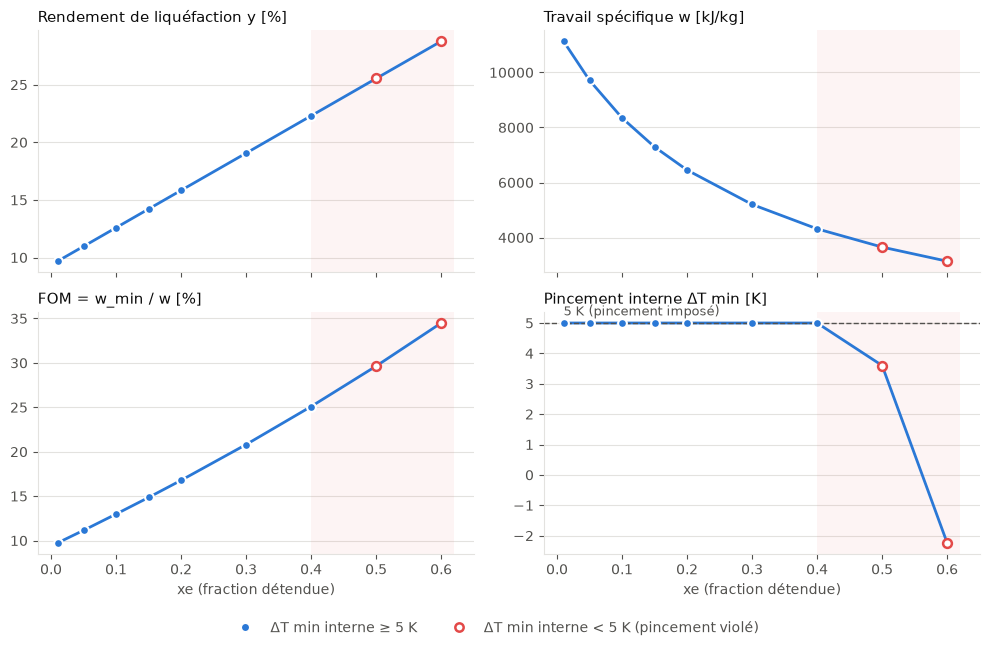

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── 1) DataFrame lisible (sans .style) ───────────────────────────────────────
df = (pd.DataFrame(results)
        .drop_duplicates("xe", keep="last")
        .sort_values("xe")
        .set_index("xe"))

out = pd.DataFrame({
    "y [%]":           df["y"] * 100,
    "ṁ_circ [kg/s]":   df["m_circ"],
    "W_comp [MW]":     df["W_comp"] / 1e6,
    "W_exp [MW]":      df["W_exp"] / 1e6,
    "W_tot [MW]":      df["W_tot"] / 1e6,
    "w [kJ/kg]":       df["w"] / 1e3,
    "w [kWh/kg]":      df["w_kWh_per_kg"],
    "FOM [%]":         df["fom"] * 100,
    "ΔT min int. [K]": df["dT_int"],
})
if "A_hot" in df:
    out["A_hot [m²]"] = df["A_hot"]

out = out.round(2).round({"w [kJ/kg]": 0, "A_hot [m²]": 0})
out        # affichage du DataFrame, plus de notation scientifique

# ── 2) Graphique : une métrique par panneau ──────────────────────────────────
INK, MUTED, GRID, BLUE, RED = "#0b0b0b", "#52514e", "#e3e2df", "#2a78d6", "#e34948"

ok = out["ΔT min int. [K]"] >= 4.99               # pincement interne respecté ?
panels = [("y [%]",           "Rendement de liquéfaction y [%]"),
          ("w [kJ/kg]",       "Travail spécifique w [kJ/kg]"),
          ("FOM [%]",         "FOM = w_min / w [%]"),
          ("ΔT min int. [K]", "Pincement interne ΔT min [K]")]

fig, axs = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
for ax, (col, title) in zip(axs.flat, panels):
    if (~ok).any():                               # zone où le pincement interne est violé
        ax.axvspan(out.index[ok].max(), out.index.max() + 0.02, color=RED, alpha=0.06, lw=0)
    ax.plot(out.index, out[col], color=BLUE, lw=2, zorder=2)
    ax.scatter(out.index[ok],  out.loc[ok,  col], s=40, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
    ax.scatter(out.index[~ok], out.loc[~ok, col], s=40, facecolor="white", edgecolor=RED, linewidth=1.8, zorder=3)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED)

ax = axs[1, 1]                                    # ligne de pincement imposé
ax.axhline(5, color=MUTED, ls="--", lw=1)
ax.text(out.index.min(), 5.15, "5 K (pincement imposé)", color=MUTED, fontsize=9, va="bottom")

for ax in axs[1]: ax.set_xlabel("xe (fraction détendue)", color=MUTED)
fig.legend(handles=[Line2D([], [], marker="o", color=BLUE, lw=0, markeredgecolor="white", label="ΔT min interne ≥ 5 K"),
                    Line2D([], [], marker="o", color="white", lw=0, markeredgecolor=RED, markeredgewidth=1.8,
                           label="ΔT min interne < 5 K (pincement violé)")],
           loc="lower center", ncol=2, frameon=False, labelcolor=MUTED)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

##